# Air Quality Under the Microscope

## Research objective

This notebook investigates the quality and patterns of
historical PM2.5 measurements across Beijing monitoring
stations. It aims to identify issues relevant to a
future machine-learning project.

The analysis is exploratory; it does not train a model
or establish causes of air pollution.

In [39]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data_folder = Path("data/raw")
files = sorted(data_folder.glob("*.csv"))

print("CSV files found:", len(files))
print(files[:3])

CSV files found: 12
[WindowsPath('data/raw/PRSA_Data_Aotizhongxin_20130301-20170228.csv'), WindowsPath('data/raw/PRSA_Data_Changping_20130301-20170228.csv'), WindowsPath('data/raw/PRSA_Data_Dingling_20130301-20170228.csv')]


In [40]:
dataframes = []

for file in files:
    station_df = pd.read_csv(file)
    dataframes.append(station_df)

df = pd.concat(dataframes, ignore_index=True)

print("Shape:", df.shape)
print("Stations:", df["station"].nunique())

df.head()

Shape: (420768, 18)
Stations: 12


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


In [41]:
print(df.shape)
print(df.dtypes)


(420768, 18)
No           int64
year         int64
month        int64
day          int64
hour         int64
PM2.5      float64
PM10       float64
SO2        float64
NO2        float64
CO         float64
O3         float64
TEMP       float64
PRES       float64
DEWP       float64
RAIN       float64
wd             str
WSPM       float64
station        str
dtype: object


In [42]:
print("Stations:",df["station"].unique())

Stations: <StringArray>
[ 'Aotizhongxin',     'Changping',      'Dingling',        'Dongsi',
      'Guanyuan',       'Gucheng',       'Huairou',  'Nongzhanguan',
        'Shunyi',       'Tiantan',        'Wanliu', 'Wanshouxigong']
Length: 12, dtype: str


In [43]:
print("Maximum value of PM2.5 : ",df["PM2.5"].max())
print("minimum value of PM2.5 : ",df["PM2.5"].min())
print("mean of PM 2.5 : ",df["PM2.5"].mean())
print("Median of PM2.5 :",df["PM2.5"].median())

Maximum value of PM2.5 :  999.0
minimum value of PM2.5 :  2.0
mean of PM 2.5 :  79.79342813248581
Median of PM2.5 : 55.0


In [44]:
missing_counts = df.isna().sum().sort_values(ascending=False)

missing_counts


CO         20701
O3         13277
NO2        12116
SO2         9021
PM2.5       8739
PM10        6449
wd          1822
DEWP         403
TEMP         398
PRES         393
RAIN         390
WSPM         318
year           0
No             0
day            0
month          0
hour           0
station        0
dtype: int64

In [45]:
missing_percent = (df.isna().mean() * 100).sort_values(
    ascending=False
)

missing_percent

CO         4.919813
O3         3.155421
NO2        2.879497
SO2        2.143937
PM2.5      2.076916
PM10       1.532674
wd         0.433018
DEWP       0.095777
TEMP       0.094589
PRES       0.093401
RAIN       0.092688
WSPM       0.075576
year       0.000000
No         0.000000
day        0.000000
month      0.000000
hour       0.000000
station    0.000000
dtype: float64

In [46]:
station_missing = (
    df.groupby("station")["PM2.5"]
      .apply(lambda values: values.isna().mean() * 100)
      .sort_values(ascending=False)
)

station_missing

station
Huairou          2.717887
Aotizhongxin     2.638033
Shunyi           2.603810
Dingling         2.221652
Changping        2.207392
Dongsi           2.138946
Wanshouxigong    1.984942
Tiantan          1.930755
Gucheng          1.842345
Nongzhanguan     1.791011
Guanyuan         1.756788
Wanliu           1.089436
Name: PM2.5, dtype: float64

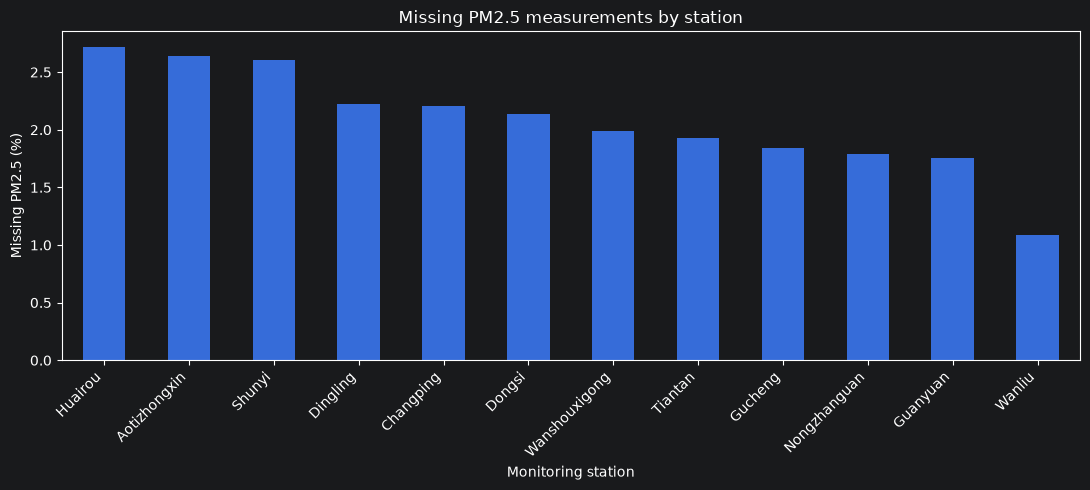

In [47]:
station_missing.plot(
    kind="bar",
    figsize=(11, 5),
    title="Missing PM2.5 measurements by station"
)

plt.ylabel("Missing PM2.5 (%)")
plt.xlabel("Monitoring station")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [48]:
print(df["PM2.5"].mean())
print(df["PM2.5"].median())
print(df["PM2.5"].std())

79.79342813248581
55.0
80.82239126019613


In [49]:
station_stats=(
    df.groupby("station")["PM2.5"]
    .agg(["mean","median","count","max","min","std"])
    .sort_values("mean",ascending=False)
)
station_status.round(2)


,mean,median,count,max,min,std
station,,,,,,
Dongsi,86.19,61.0,34314,737.0,3.0,86.58
Wanshouxigong,85.02,60.0,34368,999.0,3.0,85.98
Nongzhanguan,84.84,59.0,34436,844.0,2.0,86.23
Gucheng,83.85,60.0,34418,770.0,2.0,82.80
Wanliu,83.37,59.0,34682,957.0,2.0,81.91
Guanyuan,82.93,59.0,34448,680.0,2.0,80.93
Aotizhongxin,82.77,58.0,34139,898.0,3.0,82.14
Tiantan,82.16,59.0,34387,821.0,3.0,80.92
Shunyi,79.49,55.0,34151,941.0,2.0,81.23


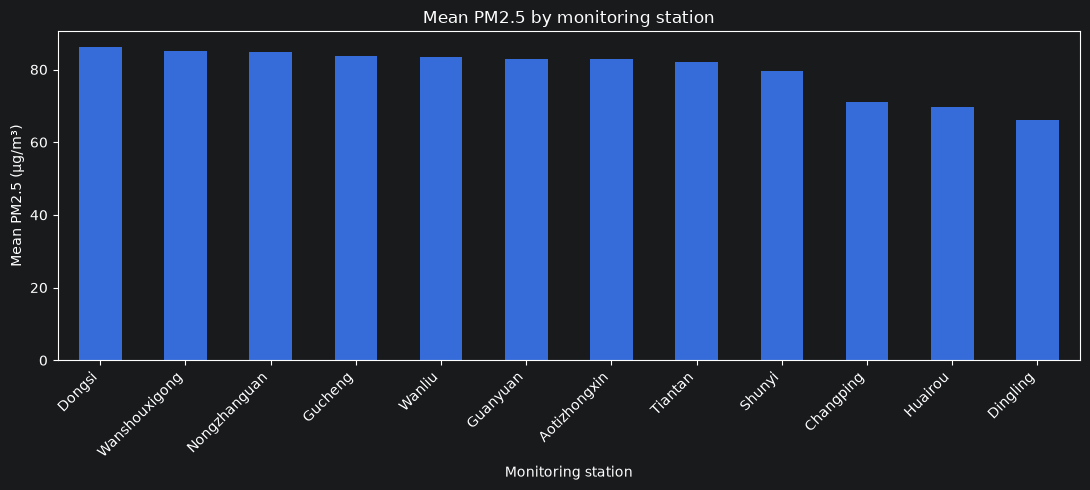

In [50]:
station_stats["mean"].plot(
    kind="bar",
    figsize=(11, 5),
    title="Mean PM2.5 by monitoring station"
)

plt.ylabel("Mean PM2.5 (µg/m³)")
plt.xlabel("Monitoring station")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

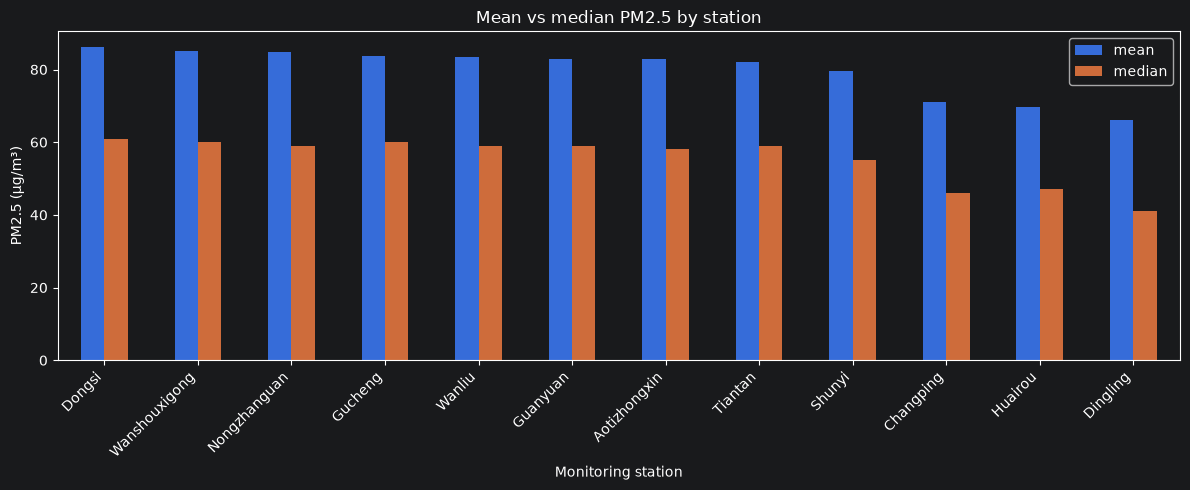

In [51]:
station_stats[["mean", "median"]].plot(
    kind="bar",
    figsize=(12, 5),
    title="Mean vs median PM2.5 by station"
)

plt.ylabel("PM2.5 (µg/m³)")
plt.xlabel("Monitoring station")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [52]:
df["datetime"] = pd.to_datetime(
    df[["year", "month", "day", "hour"]]
)

df[["datetime", "station", "PM2.5"]].head()

,datetime,station,PM2.5
0,2013-03-01 00:00:00,Aotizhongxin,4.0
1,2013-03-01 01:00:00,Aotizhongxin,8.0
2,2013-03-01 02:00:00,Aotizhongxin,7.0
3,2013-03-01 03:00:00,Aotizhongxin,6.0
4,2013-03-01 04:00:00,Aotizhongxin,3.0
